# Uji Sensitivitas Parameter Preprocessing

Lanjutan dari `pratubes-banjir-senyar.ipynb`. Tiga parameter di notebook utama dipilih dengan alasan, tapi belum diuji: ambang selisih backscatter (-3 dB), minimum mapping unit (10 piksel), dan filter speckle (Lee 7x7). notebook ini mengganti nilainya satu per satu lalu melihat seberapa besar luas genangan dan kesesuaian dengan Sentinel-2 ikut berubah

Notebook ini hanya membaca cache `../data/*.npz` yang dibuat notebook utama, jadi notebook utama harus sudah pernah dijalankan sekali

| parameter | nilai diuji | nilai notebook utama |
| --- | --- | --- |
| ambang selisih | -2, -3, -4 dB | -3 dB |
| minimum mapping unit | 5, 10, 20 piksel (0,2 / 0,4 / 0,8 ha) | 10 piksel |
| filter speckle | Lee 5x5, Lee 7x7, median 5x5 | Lee 7x7 |

In [1]:
from itertools import product
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage.filters import threshold_otsu

BASE = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA = BASE / "data"
GAMBAR = BASE / "gambar"
RES = 20
PX_HA = RES * RES / 10_000
PASANGAN = {41: ("2025-11-15", "2025-11-27"), 143: ("2025-11-16", "2025-11-28")}
S2_TANGGAL = "2025-11-29"

SELISIH = [-2.0, -3.0, -4.0]
MMU = [5, 10, 20]
FILTER = ["lee 5x5", "lee 7x7", "median 5x5"]
DASAR = {"filter": "lee 7x7", "selisih": -3.0, "mmu": 10}


def baca(nama):
    z = np.load(DATA / f"{nama}.npz")
    return {k: z[k] for k in z.files}


s1 = {(o, lab): baca(f"s1_{o}_{t}") for o, ts in PASANGAN.items() for lab, t in zip(("pre", "evt"), ts)}
wc = baca("worldcover_2021")["map"]
dem = baca("copdem30")["data"].astype("float32")
s2 = baca("s2_" + S2_TANGGAL)

## Fungsi dari Notebook Utama

Fungsi di bawah disalin tanpa perubahan dari notebook utama supaya hasil dengan parameter dasar sama persis

In [2]:
def valid_mask(lin):
    return np.isfinite(lin) & (lin > 0)


def to_db(lin):
    out = np.full(lin.shape, np.nan, dtype="float32")
    ok = valid_mask(lin)
    out[ok] = 10 * np.log10(lin[ok])
    return out


def isi_nan(img):
    out = img.astype("float32").copy()
    out[~np.isfinite(out)] = np.nanmedian(out)
    return out


def lee(lin, size, enl):
    m = cv2.blur(lin, (size, size))
    m2 = cv2.blur(lin * lin, (size, size))
    var = np.maximum(m2 - m * m, 0)
    ci2 = var / np.maximum(m * m, 1e-12)
    w = np.clip(1 - (1 / enl) / np.maximum(ci2, 1e-12), 0, 1)
    return m + w * (lin - m)


def filter_speckle(lin, nama, enl):
    x = isi_nan(np.where(valid_mask(lin), lin, np.nan))
    if nama == "median 5x5":
        out = 10 ** (cv2.medianBlur(10 * np.log10(np.maximum(x, 1e-6)), 5) / 10)
    else:
        out = lee(x, int(nama.split()[1][0]), enl)
    out = out.astype("float32")
    out[~valid_mask(lin)] = np.nan
    return out


def cari_patch_homogen(lin, darat, size=31):
    x = isi_nan(np.where(valid_mask(lin), lin, np.nan))
    m = cv2.blur(x, (size, size))
    v = np.maximum(cv2.blur(x * x, (size, size)) - m * m, 0)
    cv_map = v / np.maximum(m * m, 1e-12)
    ok = cv2.erode(darat.astype("uint8"), np.ones((size, size), np.uint8)).astype(bool)
    h = size // 2
    ok[:h], ok[-h:], ok[:, :h], ok[:, -h:] = False, False, False, False
    cv_map[~ok] = np.inf
    r, c = np.unravel_index(np.argmin(cv_map), cv_map.shape)
    return np.s_[r - h:r + h + 1, c - h:c + h + 1]


def bersihkan(mask, mmu):
    m = cv2.morphologyEx(mask.astype("uint8"), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    keep = np.zeros(n, bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= mmu
    return keep[lab]

In [3]:
gy, gx = np.gradient(cv2.blur(dem, (9, 9)), RES)
mask_lereng = np.degrees(np.arctan(np.hypot(gx, gy))) > 5
air_permanen = wc == 80
for v in s1.values():
    v["valid"] = valid_mask(v["vv"]) & valid_mask(v["vh"])

evt41 = s1[41, "evt"]
patch = cari_patch_homogen(evt41["vv"], evt41["valid"] & ~air_permanen & ~mask_lereng)
p = evt41["vv"][patch]
ENL_RAW = float(np.nanmean(p) ** 2 / np.nanvar(p))
print(f"ENL tanpa filter: {ENL_RAW:.2f} (notebook utama 19,65)")

# Referensi Sentinel-2: air MNDWI di piksel cerah, sama seperti notebook utama
offset = 1000 if float(s2["baseline"]) >= 4 else 0
g, sw = [(s2[b].astype("float32") - offset) / 10000 for b in ("B03", "B11")]
mndwi = (g - sw) / np.maximum(g + sw, 1e-6)
cerah = np.isin(s2["SCL"], [4, 5, 6, 7]) & np.isfinite(mndwi)
air_s2 = mndwi > threshold_otsu(mndwi[cerah & ~air_permanen])

ENL tanpa filter: 19.65 (notebook utama 19,65)


## Menjalankan Semua Kombinasi

Filter adalah tahap paling berat, jadi tiap filter dihitung sekali per citra, lalu ambang selisih dan MMU divariasikan di atasnya. total 3 x 3 x 3 = 27 kombinasi

Untuk tiap kombinasi dicatat:

- luas genangan baru gabungan dua orbit
- presisi dan recall genangan baru terhadap air Sentinel-2 di piksel cerah, di luar air permanen dan di luar piksel yang sudah air sebelum banjir. ini beda dengan validasi di notebook utama yang membandingkan air total, karena di sini yang diuji justru parameter tahap change detection

Selisih waktu dua hari dan keterbatasan double bounce dari notebook utama tetap berlaku, jadi angka presisi dan recall di sini dipakai untuk membandingkan kombinasi satu sama lain, bukan sebagai akurasi mutlak

In [4]:
hasil = []
for f in FILTER:
    db = {k: to_db(filter_speckle(v["vv"], f, ENL_RAW)) for k, v in s1.items()}
    per_orbit = {}
    for orbit in PASANGAN:
        pre, evt = db[orbit, "pre"], db[orbit, "evt"]
        valid = s1[orbit, "pre"]["valid"] & s1[orbit, "evt"]["valid"]
        m = s1[orbit, "evt"]["valid"] & ~air_permanen
        t = threshold_otsu(evt[m & np.isfinite(evt)])
        per_orbit[orbit] = dict(t=t, valid=valid, pre=pre, evt=evt,
                                air_pre=valid & (pre < t), air_evt=valid & (evt < t))
    v41 = per_orbit[41]["valid"]
    air_pre = np.where(v41, per_orbit[41]["air_pre"], per_orbit[143]["air_pre"])
    uji = cerah & (v41 | per_orbit[143]["valid"]) & ~air_permanen & ~mask_lereng & ~air_pre
    ref = air_s2[uji]
    for sel, mmu in product(SELISIH, MMU):
        peta = {}
        for orbit, o in per_orbit.items():
            kandidat = o["air_evt"] & ~o["air_pre"] & ((o["evt"] - o["pre"]) < sel) & ~air_permanen & ~mask_lereng
            peta[orbit] = bersihkan(kandidat, mmu)
        gabung = np.where(v41, peta[41], peta[143])
        pred = gabung[uji]
        tp = np.sum(pred & ref)
        hasil.append(dict(filter=f, selisih=sel, mmu=mmu, luas=gabung.sum() * PX_HA,
                          presisi=tp / max(pred.sum(), 1), recall=tp / max(ref.sum(), 1)))
    print(f"{f}: ambang Otsu orbit 41 {per_orbit[41]['t']:.2f} dB, orbit 143 {per_orbit[143]['t']:.2f} dB")

for h in hasil:
    h["f1"] = 2 * h["presisi"] * h["recall"] / max(h["presisi"] + h["recall"], 1e-9)

lee 5x5: ambang Otsu orbit 41 -12.33 dB, orbit 143 -12.83 dB


lee 7x7: ambang Otsu orbit 41 -12.23 dB, orbit 143 -12.83 dB


median 5x5: ambang Otsu orbit 41 -12.32 dB, orbit 143 -12.93 dB


In [5]:
dasar = next(h for h in hasil if h["filter"] == DASAR["filter"] and h["selisih"] == DASAR["selisih"]
             and h["mmu"] == DASAR["mmu"])
print(f"{'filter':<12}{'selisih':>8}{'mmu':>5}{'luas (ha)':>11}{'beda':>8}{'presisi':>9}{'recall':>8}{'F1':>7}")
for h in hasil:
    tanda = "  <- dasar" if h is dasar else ""
    print(f"{h['filter']:<12}{h['selisih']:>8.0f}{h['mmu']:>5}{h['luas']:>11,.0f}"
          f"{(h['luas'] / dasar['luas'] - 1):>+8.1%}{h['presisi']:>9.3f}{h['recall']:>8.3f}{h['f1']:>7.3f}{tanda}")

filter       selisih  mmu  luas (ha)    beda  presisi  recall     F1
lee 5x5           -2    5     27,818   +2.0%    0.913   0.599  0.724
lee 5x5           -2   10     27,651   +1.3%    0.913   0.596  0.721
lee 5x5           -2   20     27,315   +0.1%    0.914   0.589  0.717
lee 5x5           -3    5     27,627   +1.3%    0.913   0.596  0.721
lee 5x5           -3   10     27,467   +0.7%    0.914   0.593  0.719
lee 5x5           -3   20     27,136   -0.5%    0.914   0.586  0.714
lee 5x5           -4    5     27,220   -0.2%    0.915   0.588  0.716
lee 5x5           -4   10     27,065   -0.8%    0.915   0.585  0.714
lee 5x5           -4   20     26,744   -2.0%    0.915   0.579  0.709
lee 7x7           -2    5     27,627   +1.3%    0.912   0.596  0.721
lee 7x7           -2   10     27,467   +0.7%    0.913   0.592  0.718
lee 7x7           -2   20     27,145   -0.5%    0.913   0.586  0.714
lee 7x7           -3    5     27,439   +0.6%    0.913   0.592  0.718
lee 7x7           -3   10     27,2

## Satu Parameter Berubah, Dua Lainnya Tetap

Tabel lengkap di atas sulit dibaca sekaligus, jadi grafik di bawah hanya mengubah satu parameter sementara dua lainnya tetap di nilai dasar

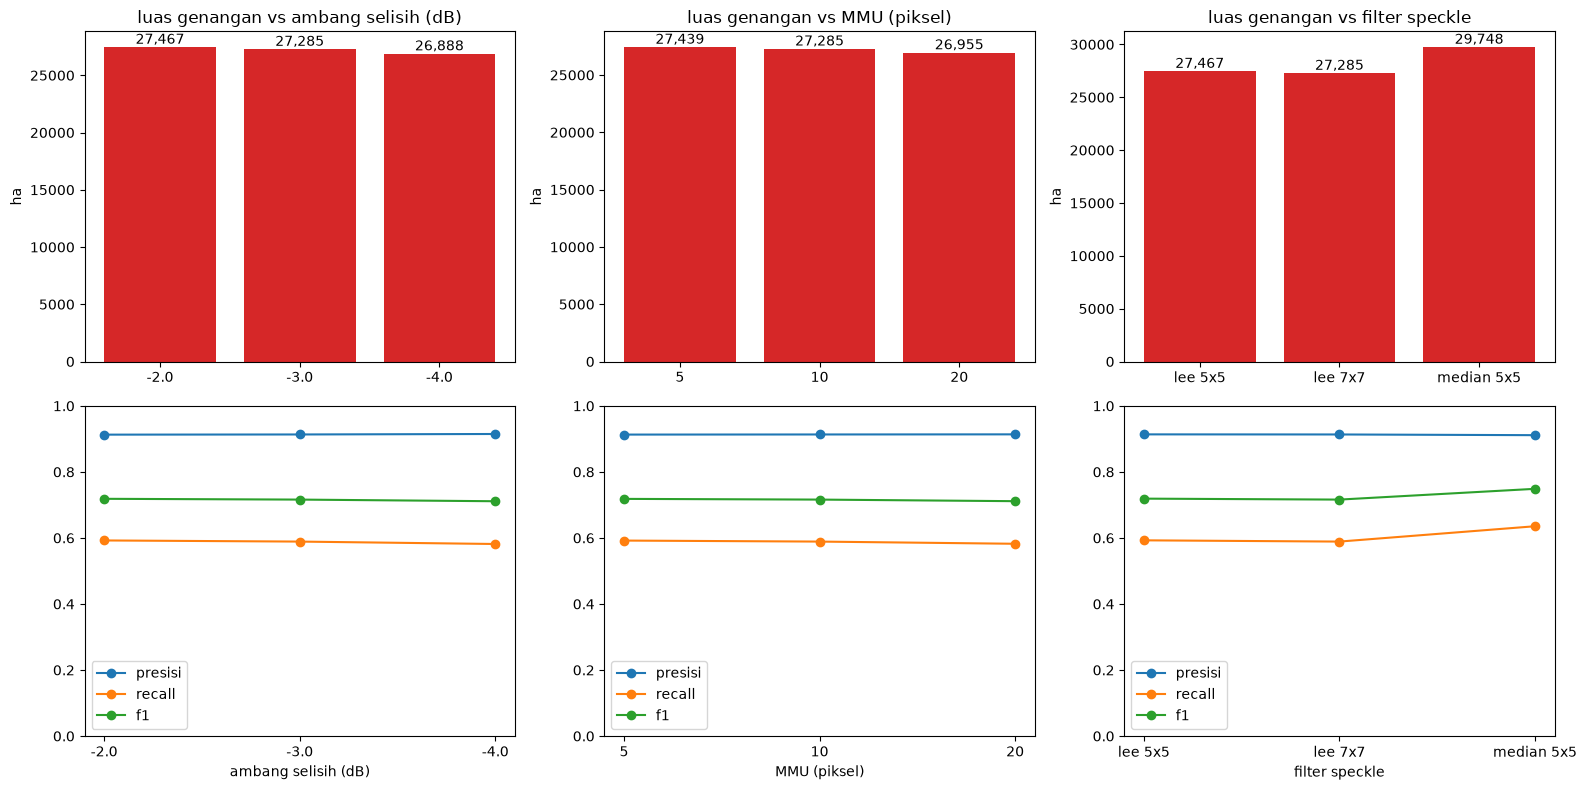

In [6]:
def oat(kunci, nilai):
    out = []
    for n in nilai:
        syarat = {**DASAR, kunci: n}
        out.append(next(h for h in hasil if all(h[k] == syarat[k] for k in DASAR)))
    return out


fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for c, (kunci, nilai, label) in enumerate((("selisih", SELISIH, "ambang selisih (dB)"),
                                          ("mmu", MMU, "MMU (piksel)"),
                                          ("filter", FILTER, "filter speckle"))):
    rows = oat(kunci, nilai)
    x = [str(n) for n in nilai]
    ax[0, c].bar(x, [r["luas"] for r in rows], color="tab:red")
    ax[0, c].set_title(f"luas genangan vs {label}")
    ax[0, c].set_ylabel("ha")
    for i, r in enumerate(rows):
        ax[0, c].text(i, r["luas"], f"{r['luas']:,.0f}", ha="center", va="bottom")
    for m, warna in (("presisi", "tab:blue"), ("recall", "tab:orange"), ("f1", "tab:green")):
        ax[1, c].plot(x, [r[m] for r in rows], marker="o", color=warna, label=m)
    ax[1, c].set_ylim(0, 1)
    ax[1, c].set_xlabel(label)
    ax[1, c].legend()
plt.tight_layout()
plt.savefig(GAMBAR / "07-sensitivitas-parameter.png", dpi=110, bbox_inches="tight")
plt.show()

In [7]:
luas = np.array([h["luas"] for h in hasil])
print(f"rentang luas 27 kombinasi: {luas.min():,.0f} sampai {luas.max():,.0f} ha "
      f"({luas.min() / dasar['luas'] - 1:+.1%} sampai {luas.max() / dasar['luas'] - 1:+.1%} dari dasar)")
for kunci, nilai in (("selisih", SELISIH), ("mmu", MMU), ("filter", FILTER)):
    rows = oat(kunci, nilai)
    l = [r["luas"] for r in rows]
    print(f"{kunci:<8} mengubah luas {max(l) - min(l):>7,.0f} ha ({(max(l) - min(l)) / dasar['luas']:.1%} dari dasar)")
terbaik = max(hasil, key=lambda h: h["f1"])
print(f"F1 tertinggi: {terbaik['filter']}, {terbaik['selisih']:.0f} dB, MMU {terbaik['mmu']} -> F1 {terbaik['f1']:.3f}"
      f" (dasar {dasar['f1']:.3f})")

rentang luas 27 kombinasi: 26,570 sampai 30,114 ha (-2.6% sampai +10.4% dari dasar)
selisih  mengubah luas     578 ha (2.1% dari dasar)
mmu      mengubah luas     484 ha (1.8% dari dasar)
filter   mengubah luas   2,464 ha (9.0% dari dasar)
F1 tertinggi: median 5x5, -2 dB, MMU 5 -> F1 0.753 (dasar 0.716)


## Pembahasan

Parameter dasar menghasilkan 27.285 ha, sama dengan notebook utama, jadi fungsi yang disalin tidak bergeser. dari 27 kombinasi, luas genangan berada di rentang 26.570 sampai 30.114 ha (-2,6% sampai +10,4% dari dasar)

Ambang selisih dan MMU hampir tidak berpengaruh. mengganti ambang selisih dari -2 ke -4 dB hanya mengubah luas 578 ha (2,1%), dan MMU 5 sampai 20 piksel hanya 484 ha (1,8%). untuk ambang selisih ini masuk akal: piksel yang lolos syarat air saat banjir (di bawah sekitar -12 dB) dan bukan air sebelumnya (di atas ambang yang sama) hampir selalu sudah turun lebih dari 4 dB, jadi syarat selisih jarang menjadi penentu. untuk MMU, sebagian besar piksel lepas sudah dibuang opening 3x3 sebelum MMU bekerja

Filter speckle yang paling menentukan, 2.464 ha (9,0%). Lee 5x5 dan Lee 7x7 hampir sama, beda 0,7%. median 5x5 memberi luas sekitar 9% lebih besar

Hasil ini mengoreksi alasan pemilihan filter di notebook utama. di sana Lee 7x7 dipilih karena median menghapus pematang dan jalan, dengan dugaan luas genangan jadi melebar. luasnya memang melebar, tapi presisi terhadap Sentinel-2 tetap sama (0,911 untuk median, 0,913 untuk Lee 7x7) sementara recall naik dari 0,589 ke 0,635, dan F1 dari 0,716 ke 0,749. artinya tambahan luas dari median sebagian besar juga air menurut Sentinel-2, bukan genangan palsu

Ada dua catatan sebelum mengganti filter. pertama, band SWIR Sentinel-2 yang dipakai MNDWI beresolusi asli 20 m, jadi referensinya sendiri tidak bisa melihat pematang selebar satu dua piksel. filter yang menghaluskan pematang wajar terlihat lebih cocok dengan referensi yang juga halus. kedua, validasi ini selisih dua hari dengan citra radar. karena itu notebook utama belum diubah. keputusan filter lebih tepat diambil sesudah ada pembanding yang lebih tajam, misalnya digitasi manual beberapa petak dari Sentinel-2 10 m

Recall genangan baru di semua kombinasi berkisar 0,58 sampai 0,64, lebih rendah dari recall air total di notebook utama (0,697). sisa air yang terlewat tetap konsisten dengan keterbatasan double bounce di vegetasi dan permukiman, dan tidak bisa diperbaiki hanya dengan menggeser tiga parameter ini